# Exploratory Data Analysis

Notebook khảo sát:
- Quy mô dữ liệu và phân bố Ham/Spam.
- Độ dài tin nhắn và mối liên hệ với nhãn.
- Từ khóa và dấu hiệu Spam.

## 1. Dữ liệu và phân bố nhãn

In [1]:
from data_loader import load_sms_data
raw_data = load_sms_data("../data/raw/SMSSpamCollection")
clean_data = load_sms_data("../data/processed/sms_clean.tsv")

ham_texts = []
spam_texts = []
for label, text in clean_data:
    if label == "ham":
        ham_texts.append(text)
    else:
        spam_texts.append(text)

print(f"Raw: {len(raw_data)} | Clean: {len(clean_data)} (Ham: {len(ham_texts)}, Spam: {len(spam_texts)})")

Raw: 5574 | Clean: 5159 (Ham: 4518, Spam: 641)


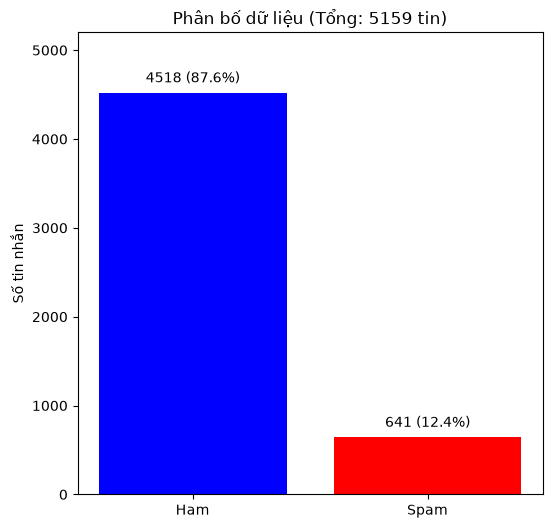

In [2]:
import matplotlib.pyplot as plt

ham_count = len(ham_texts)
spam_count = len(spam_texts)
total = ham_count + spam_count

plt.figure(figsize=(6, 6))
plt.bar(
    ["Ham", "Spam"],
    [ham_count, spam_count],
    color=["blue", "red"]
)
plt.title(f"Phân bố dữ liệu (Tổng: {total} tin)")
plt.ylabel("Số tin nhắn")
plt.ylim(0, 5200)

# plt.text(x, y, "chữ")
plt.text(0, ham_count + 120, f"{ham_count} ({ham_count/total*100:.1f}%)", ha="center")
plt.text(1, spam_count + 120, f"{spam_count} ({spam_count/total*100:.1f}%)", ha="center")

plt.show()

**Finding:**
- Từ 5.574 bản ghi ban đầu còn 5.159 sau làm sạch (loại 415 tin trùng). Ham chiếm 87.6%, nên mô hình luôn đoán Ham vẫn đạt 87.6% accuracy nhưng sẽ bỏ sót toàn bộ Spam.

-> Khi đánh giá mô hình cần xem thêm precision, recall và F1 thay vì chỉ dựa vào accuracy.

-> Hàm loss cần có trọng số để khử việc mất cân bằng trong dữ liệu.

-> Xem xét việc bổ sung dữ liệu offline cho Spam.

## 2. Độ dài tin nhắn

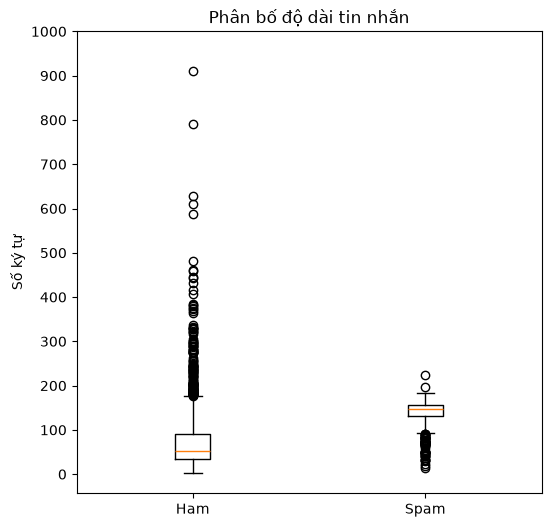

In [3]:
ham_lens = []
spam_lens = []

for t in ham_texts:
    ham_lens.append(len(t))

for t in spam_texts:
    spam_lens.append(len(t))

plt.figure(figsize=(6, 6))
plt.boxplot([ham_lens, spam_lens], tick_labels=["Ham", "Spam"])
plt.title("Phân bố độ dài tin nhắn")
plt.ylabel("Số ký tự")
plt.yticks(range(0, max(ham_lens + spam_lens) + 100, 100))
# plt.ylim(0, 500)

plt.show()

In [4]:
def check_stats(name, texts):
    shortest = texts[0]
    longest = texts[0]
    total_chars = 0

    for t in texts:
        total_chars += len(t)
        if len(t) < len(shortest):
            shortest = t
        if len(t) > len(longest):
            longest = t

    avg_len = total_chars / len(texts)

    print(f"{name} (Tổng: {len(texts)})")
    print(f"Min: {len(shortest)} | Avg: {avg_len:.1f} | Max: {len(longest)}")
    print(f"-> Mẫu Min: '{shortest}'")
    print(f"-> Mẫu Max: '{longest}'")
    print()


check_stats("HAM", ham_texts)
check_stats("SPAM", spam_texts)

HAM (Tổng: 4518)
Min: 2 | Avg: 70.9 | Max: 910
-> Mẫu Min: 'Ok'
-> Mẫu Max: 'For me the love should start with attraction.i should feel that I need her every time around me.she should be the first thing which comes in my thoughts.I would start the day and end it with her.she should be there every time I dream.love will be then when my every breath has her name.my life should happen around her.my life will be named to her.I would cry for her.will give all my happiness and take all her sorrows.I will be ready to fight with anyone for her.I will be in love when I will be doing the craziest things for her.love will be when I don't have to proove anyone that my girl is the most beautiful lady on the whole planet.I will always be singing praises for her.love will be when I start up making chicken curry and end up makiing sambar.life will be the most beautiful then.will get every morning and thank god for the day because she is with me.I would like to say a lot..will tell later..'

SPAM (Tổng

**Finding:** 
- Tin nhắn Spam nằm quanh giới hạn 140-160 ký tự (trung vị ~150), trong khi Ham ngắn hơn nhiều (trung vị ~50) nhưng phân tán rộng với dải outlier dài tới 910 ký tự.

## 3. Từ khóa và dấu hiệu Spam

In [5]:
from collections import Counter
import string

ham_words = Counter()
spam_words = Counter()

def get_words(text):
    for char in string.punctuation:
        text = text.replace(char, " ") # thay dấu câu bằng khoảng trắng

    words = []
    for w in text.lower().split(): # tách từ theo khoảng trắng
        if w.isalpha() and len(w) >= 2: # chỉ lấy từ thuần chữ cái và dài từ 2 ký tự trở lên
            words.append(w)
    return words


for t in ham_texts:
    ham_words.update(get_words(t))

for t in spam_texts:
    spam_words.update(get_words(t))

print(f"{'Từ khóa'}: {'Số lần ở Spam'} | {'Số lần ở Ham'}")

for word, spam_cnt in spam_words.most_common(100):
    ham_cnt = ham_words.get(word, 0)
    if spam_cnt >= 20 and spam_cnt > ham_cnt * 3:
        print(f"{word}: {spam_cnt} | {ham_cnt:}")



Từ khóa: Số lần ở Spam | Số lần ở Ham
free: 190 | 56
txt: 132 | 14
stop: 111 | 34
mobile: 105 | 13
claim: 95 | 0
www: 81 | 1
prize: 79 | 0
cash: 64 | 12
uk: 59 | 1
won: 58 | 19
urgent: 57 | 5
nokia: 53 | 2
service: 49 | 3
contact: 49 | 10
win: 47 | 8
com: 47 | 12
tone: 42 | 0
co: 41 | 1
guaranteed: 41 | 0
per: 40 | 9
customer: 38 | 8
cs: 36 | 0
draw: 33 | 5
awarded: 31 | 0
video: 31 | 2
line: 31 | 7
wk: 29 | 8
latest: 28 | 3
shows: 28 | 5
landline: 28 | 1
code: 27 | 1
ringtone: 27 | 0
box: 27 | 5
receive: 26 | 5
rate: 25 | 2
apply: 25 | 2
po: 25 | 3
camera: 24 | 3
award: 24 | 1
offer: 24 | 7


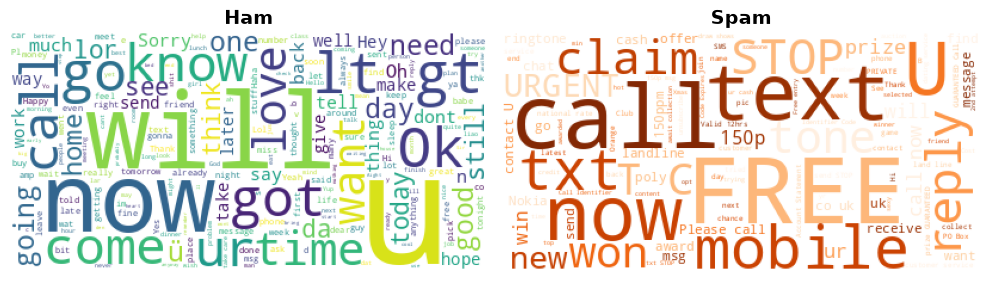

In [6]:
from wordcloud import WordCloud

ham_full_text = " ".join(ham_texts)
spam_full_text = " ".join(spam_texts)

ham_wc = WordCloud(background_color="white").generate(ham_full_text)

spam_wc = WordCloud(background_color="white", colormap="Oranges").generate(spam_full_text)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(ham_wc)
axes[0].set_title("Ham", fontsize=14, fontweight="bold")
axes[0].axis("off")

axes[1].imshow(spam_wc)
axes[1].set_title("Spam", fontsize=14, fontweight="bold")
axes[1].axis("off")

plt.tight_layout()
plt.show()

**Finding:**
- Có thể thấy Ham thiên về hội thoại, còn Spam thường nhắc đến các từ quảng cáo/ưu đãi/giải thưởng như “free”, “claim”, “prize”, "cash" và “urgent” xuất hiện nổi bật ở Spam (ít nhất 20 lần và nhiều hơn Ham trên 3 lần).

### Dấu hiệu trong tin nhắn


In [7]:
symbol_counts = {}

for label, text in clean_data:
    for char in text:
        if not char.isalnum() and not char.isspace():
            symbol_counts[char] = symbol_counts.get(char, 0) + 1

for symbol in symbol_counts:
    print(f"{symbol!r}: {symbol_counts[symbol]} lần")

',': 1719 lần
'.': 10153 lần
'(': 107 lần
')': 447 lần
'&': 815 lần
"'": 1805 lần
'!': 1246 lần
'?': 1490 lần
'£': 268 lần
'*': 285 lần
'>': 30 lần
'/': 367 lần
'+': 107 lần
':': 651 lần
'=': 43 lần
'-': 529 lần
';': 681 lần
'#': 263 lần
'"': 289 lần
'@': 34 lần
'$': 23 lần
'~': 3 lần
'|': 36 lần
'_': 11 lần
'<': 6 lần
'\\': 2 lần
'^': 1 lần
'%': 10 lần
'[': 5 lần
']': 5 lần


**Finding:** Trong danh sách ký hiệu, có hai ký hiệu tiền tệ là `£` (268 lần) và `$` (23 lần). Đây là số lần ký tự xuất hiện, không phải số tin nhắn, chưa tính cách viết tiền bằng chữ.

In [8]:
def has_money_sign(t):
    if ("£" in t) or ("$" in t):
        return True
    return False


def has_url(t):
    t_lower = t.lower()
    for s in ("http", "www.", ".com", ".co.uk", ".net", ".org"):
        if s in t_lower:
            return True
    return False


def has_uppercase_word(t): 
    for w in t.split():
        if w.isupper() and len(w) >= 3:
            return True
    return False

feature_lists = [
    ("Ký hiệu tiền (£/$)", has_money_sign),
    ("Link URL", has_url),
    ("Từ IN HOA (>=3 chữ)", has_uppercase_word),
]

for feat, check in feature_lists:
    ham_cnt = 0
    spam_cnt = 0

    for t in ham_texts:
        if check(t):
            ham_cnt += 1
    for t in spam_texts:
        if check(t):
            spam_cnt += 1

    total = ham_cnt + spam_cnt
    print(f"{feat}")
    print(f"Ham : {ham_cnt}/{len(ham_texts)} ({ham_cnt / len(ham_texts) * 100:.1f}%)")
    print(f"Spam: {spam_cnt}/{len(spam_texts)} ({spam_cnt / len(spam_texts) * 100:.1f}%)")
    print(f"{spam_cnt / total * 100:.1f}% là Spam\n")

Ký hiệu tiền (£/$)
Ham : 19/4518 (0.4%)
Spam: 214/641 (33.4%)
91.8% là Spam

Link URL
Ham : 13/4518 (0.3%)
Spam: 117/641 (18.3%)
90.0% là Spam

Từ IN HOA (>=3 chữ)
Ham : 288/4518 (6.4%)
Spam: 464/641 (72.4%)
61.7% là Spam



**Finding:** Ký hiệu tiền và URL có ~90-92% là Spam, còn từ IN HOA có độ phủ lớn (72.4% tin Spam).

-> Cần giữ lại các dấu hiệu này thay vì xóa hay lower ở bước tiền xử lý.